<div style="text-align: center"><img src="https://telematica.usm.cl/wp-content/themes/telematica-web/assets/img/header-usm.png" height="75"></div>

# Tarea 3 Módulos 2 y 3: Cifrado Asimétrico
### Asignatura: Criptografía y Seguridad de la Información - TEL252 - 2026
#### Docente y Autor : Berioska Contreras Vargas - berioska.contreras@usm.cl

* **Exponenciación modular:** Reducción residual de un número entero positivo $m$ y de potencia $e$. La base $m$ representa un fragmento de mensaje en el rango $\{{0,...,n-1}\}$,siendo $n$ un número primo y $Zₙ^*$  un conjunto multiplicativo dado por $\phi(n)$. Si $m^e$ $mod$ $n$ $=$ $m$^$(e$ $mod$ $\phi(n))$ $mod$ $n$, entonces es posible encontrar otra exponenciación equivalente en $Zₙ^*$.

In [1]:
import math
n= bytes([23])
m, e = bytes([3]), bytes([4])
serie = bytearray(n)+bytearray(m)+bytearray(e)
print(serie)
exp = serie[1]**serie[2]
print(exp % serie[0]) # 3^(4)=12(mod23)
print(serie[1]**(4+11) % serie[0]) # 3^(4+11)=12(mod23)
print(serie[1]**22 % serie[0]) # 3^(22)=1(mod23)

bytearray(b'\x17\x03\x04')
12
12
1


* **Logaritmo Discreto Modular:** Función inversa de una expresión exponencial que pertenece a un grupo finito dado por $Z_n$ siendo $n$ el resultado del producto entre dos números primos grandes y aleatorios $p \cdot q$. Notar que el valor $n$ es público, sin embargo los valores $p$ y $q$ se mantendrán ocultos siendo difícil factorizar $n$.

In [2]:
import math
import numpy as np
n, b, x, y = 23, 3, 4, 5
serie = np.array([n,b,x,y])
Kx, Ky = b**x % n, b**y % n # exp.#1 - llave pública (public key)
print(True) if Kx == Ky else print(False) 
SSx, SSy = (b**y)**x % n, (b**x)**y % n # exp.#2 llave compartida (shared secret)
print(True) if SSx == SSy else print(False) 
for e in range(n):
    print(math.log((b**e),10))

False
True
0.0
0.47712125471966244
0.9542425094393249
1.4313637641589871
1.9084850188786497
2.3856062735983117
2.8627275283179743
3.339848783037637
3.8169700377572995
4.294091292476962
4.771212547196623
5.248333801916287
5.725455056635949
6.202576311355611
6.679697566075274
7.156818820794936
7.633940075514599
8.11106133023426
8.588182584953923
9.065303839673586
9.542425094393247
10.019546349112911
10.496667603832574


* **Validación de Kpub en RSA:** Sabemos que mediante el algoritmo EEA podemos calcular las llave pública, tal que se se encuentra en el rango $0 < e < \phi(n)$. Si $mcd(q,\phi(n)) = 1$ entonces $Kpub = e$, de otro modo seguiremos la búsqueda.

In [3]:
import math
import secrets as prng
def myphi(u,v):
    eu = (u-1)*(v-1)
    return eu
p, q = bytes([5]), bytes([23])
e = int.from_bytes(p, byteorder='big', signed=False)
print(math.gcd(myphi(prng.choice(p),prng.choice(q)),e))
print(math.gcd(6,7))

1
1


* **Cifrado de Logaritmo Discreto:** La llave  de cifrado es un par de números enteros positivos $(e,n)$ y la llave de descifrado el par $(d,n)$. Siendo $d$ un valor entero aleatorio que satisface $gcd(d,(p-1)*(q-1))=1$. Luego, el valor $e$ es derivado de $p$,$q$ y $d$, siendo un inverso multiplicativo de $d$, módulo $(p-1)*(q-1)$, tal que $e$*$d$ $=$ $1$ $mod$ $\phi(n)$. Finalmente, una llave pública $(e,n)$ es compartida, los parámetros $n$, $e$ y $m^e$ son transmitidos por el receptor para que el emisor cifre.

In [4]:
import math
import numpy as np
def eea(r0,r1):
    if r0 == 0:
        return (r1, 0, 1)
    else:
        g, s, t = eea(r1 % r0, r0)
        return (g, t - (r1 // r0) * s, s)
def euler(a,b):
    return (a-1)*(b-1)
def inv(cff):
    return cff[2] % phi_n
p, q = bytes([3]), bytes([11])
e = bytes([3])
phi_n = euler(bytearray(p)[0],bytearray(q)[0])
cff = np.array(eea(phi_n,bytearray(e)[0]))
print(cff)
print(phi_n)
if (inv(cff)*bytearray(e)[0]) % phi_n == 1:
    n = bytearray(p)[0]*bytearray(q)[0]
    kpub = (n,bytearray(e)[0])
print(kpub)

[ 1 -1  7]
20
(33, 3)


* **Descifrado de Logaritmo Discreto:** Sea la llave privada el par $(d,n)$, es posible notar que $d$ es un valor coprimo de $phi(n)$. Si $e$*$d$ = $1 (mod (p-1)*(q-1))$ = $1$ $(mod$ $n - (p+q) +1)$ = $1$ $(mod$ $\phi(n))$. De este modo, $m$^$(e*d)$ = $m$^$(k*\phi(n)+1)$ $mod$ $(n)$ = $m$ $(mod$ $(n))$

In [5]:
import math
import numpy as np
x = bytes([4])
kpub = bytes([33,3])
kpriv = bytes([7 % 33])
y = bytearray(x)[0]**bytearray(kpub)[1] % bytearray(kpub)[0]
print(y)
#x = y**bytearray(kpriv)[0] % bytearray(kpub)[0]
sign = bytearray(x)[0]**bytearray(kpriv)[0] % bytearray(kpub)[0]
print(sign)
check = sign**bytearray(kpub)[1] % bytearray(kpub)[0]
print(check)

31
16
4


**Actividad 1**: Existen diversos algoritmos que permiten despejar $m$ de manera más o menos eficiente. Para esta actividad, veremos el _**Pohlig-Hellman algorithm**_. Investigue su funcionamiento y desarrolle una implementación propia del algoritmo. Para guiar un poco el proceso, se considera lo siguiente:
* En RSA, la llave privada $d$ se obtiene a través de $\phi (n)$. En un DLP, $m$ se obtiene a través de $\phi (p) = p - 1$. Así, nos interesa saber cómo factorizar $\phi (p)$
* Si obtenemos los factores de $\phi (p)$, entonces podemos subdividir el problema en un sistema de congruencias. Tal sistema se resuelve a través del CRT (_Chinese Remainder Theorem_)
* Se interceptó el tráfico de datos de una conexión cifrada con Elgamal, el cual contenía el siguiente código:

In [6]:
# DHKE public parameters
# Prime p
p = 11805217175667888115840516101006175607012549121531103
# Generator g
alpha = 5
# Order q
q = 11805217175667888115840516101006175607012549121531102
beta = 5141385654948906786986411820201776245790275570635546
kE = 7697644299122149488985024401911228371471164969577347
c = 10694745992609588540033984592343387427632594963228641

# Square and Multiply
def sqm(a, b, n):
    res = 1
    binarray = [int(x) for x in bin(int(b))[2:]]
    for i in binarray:
        if i == 1:
            res = (res * res * a) % n
        else:
            res = (res * res) % n
    return res

def solve_crt(dlogs, factors):
    n = 1
    for i in factors:
        n *= i
    x = 0
    for i in range(len(dlogs)):
        yi = n // factors[i]
        zi = mod_inverse(yi, factors[i])
        x += dlogs[i] * yi * zi
    return x % n

Analíce el código previo y encuentre el mensaje original con su implementación propuesta.

**Referencias:**
* https://koclab.cs.ucsb.edu/teaching/ecc/project/2015Projects/Sommerseth+Hoeiland.pdf
* https://github.com/christiankrug/pohlig_hellman/blob/master/main.py
* https://hgarrereyn.gitbooks.io/th3g3ntl3man-ctf-writeups/content/2017/picoCTF_2017/problems/cryptography/ECC2/ECC2.html
* https://en.wikipedia.org/wiki/Pohlig–Hellman_algorithm#The_general_algorithm
* https://github.com/diogoaj/ctf-writeups/blob/master/2017/picoctf/cryptography/ECC2-200/README.md

### **Actividad 2 :** Proponga y desarrolle un ataque de búsqueda exhaustiva (división de prueba) que, dado ($n = p \cdot q$) con ($p$) y ($q$) primos pequeños, recupere los factores y, a partir de ellos, la llave privada.

- Genere un par RSA de prueba: primos $p$ y $q$ de 16 a 24 bits, $n = p q$, exponente público $e$ coprimo con $\varphi(n) = (p-1)(q-1)$, y $d \equiv e^{-1} \pmod{\varphi(n)}$. Publique solo $(n, e)$.
- Implemente la factorización por búsqueda exhaustiva: pruebe enteros impares $t = 3, 5, \ldots, \lfloor\sqrt{n}\rfloor$ hasta hallar un divisor de $n$. Recupere $p$, $q$, $\varphi(n)$ y $d$.
- Verifique el ataque: cifre un mensaje $m < n$ con $c \equiv m^e \pmod{n}$ y recupere $m \equiv c^d \pmod{n}$.
- Mida (o estime) el número de pruebas en función de $\sqrt{n}$ y discuta por qué el mismo método no escala a $n$ de 1024 o 2048 bits.

### Solución

In [7]:
import secrets as shh
from sympy import primerange
from typing import Tuple, List
import math

In [8]:
# Herramientas

def euclides_extendido(a, b):
    """
    Algoritmo de Euclides Extendido.
    
    Retorna (g, s, t) tales que:
        a * s + b * t = g = gcd(a, b)
    
    Si gcd(a, b) = 1, entonces 's' es el inverso multiplicativo
    de 'a' módulo 'b' (y 't' lo es de 'b' módulo 'a').
    """
    # Condiciones iniciales
    r0, r1 = a, b
    s0, s1 = 1, 0
    t0, t1 = 0, 1
    
    while r1 != 0:
        q = r0 // r1
        r0, r1 = r1, r0 - q * r1
        s0, s1 = s1, s0 - q * s1
        t0, t1 = t1, t0 - q * t1
    
    return r0, s0, t0   # g, s, t

def inverso_modular(a, m):
    """
    Calcula el inverso multiplicativo de 'a' módulo 'm'.
    Lanza ValueError si no existe (es decir, si gcd(a, m) != 1).
    """
    g, s, _ = euclides_extendido(a, m)
    if g != 1:
        raise ValueError(f"{a} no tiene inverso módulo {m} (gcd = {g})")

    return s % m

In [9]:
def gen_rsa(lista_primos: List[int]) -> Tuple[int, int]: # n, e

    p = shh.choice(lista_primos)
    q = shh.choice(lista_primos)
    while q == p:
      q = shh.choice(lista_primos)

    n = p*q
    phi_n = (p-1)*(q-1)
    e = 0
    e_was_found = False
    while not e_was_found:
        e = shh.randbelow(phi_n)
        if e == p or e == q:
            continue
        if math.gcd(e, phi_n) == 1 and e > 1:
            e_was_found = True
    return (n, e)

In [10]:
def factorizar_exhaustiva_impares(n: int, e: int)-> Tuple[int, int, int, int, int]: # p, q, phi_n, d, iteraciones
    
    cota_superior = math.floor(math.sqrt(n))
    divisor_encontrado = False
    generado = 3 # Omitir caso trivial n % 1 = 0
    phi_n = 0
    p = 0
    q = 0
    
    iteraciones = 0
    
    while (generado <= cota_superior) and not divisor_encontrado:
        
        if n % generado == 0: # La división no arrojó resto, entonces es factor
            
            q = generado
            p = n//q # n/generado = p <-> generado = q (o viceversa)
            phi_n = (p-1)*(q-1)
            
            d = inverso_modular(e,phi_n)

            if (e*d) % phi_n == 1:
                divisor_encontrado = True
                #print(f"p = {p}, q = {q}, phi_n = {phi_n}, d = {d}, iteraciones hechas: {iteraciones}")
                #print(f" e*d mod phi_n = {(e*d) % phi_n}")
                return (p, q, phi_n, d, iteraciones)

        iteraciones += 1
        generado += 2

    raise ValueError("No se encontraron factores de 'n' con este método")
    

In [11]:
# Lista de primos - Demora un par de segundos
min = 65535
max = 16777215

lista_primos = list(primerange(min, max))

In [12]:
n, e = gen_rsa(lista_primos)
print(f" (n,e) = {(n,e)}")
p, q, phi_n, d, iteraciones = factorizar_exhaustiva_impares(n, e)

 (n,e) = (41468064985903, 15824739851369)


In [13]:
m = shh.randbelow(n)
c = pow(m, e, n) 
m_recuperado = pow(c, d, n)
print(f" Mensaje: {m}. Cifrado: {c}. Descifrado: {m_recuperado}")

 Mensaje: 18334077525318. Cifrado: 8931224075020. Descifrado: 18334077525318


### Medición de complejidad
A continuación se muestra el comportamiento de este método de búsqueda exhaustiva, en función del orden de magnitud para $n$

In [14]:
cantidad_iteraciones = 500

In [15]:
import time
import numpy as np
from IPython.display import Audio
sound_file = 'bell.wav'

In [32]:
iteraciones_por_ejecucion = np.empty(cantidad_iteraciones)
n_por_ejecucion = np.empty(cantidad_iteraciones)
iteraciones_totales_experimento = 0

tiempo_experimento = 0


for i in range(cantidad_iteraciones):
    n, e = gen_rsa(lista_primos)
    
    inicio_cronometro = time.perf_counter() # Inicio cronómetro 
    p, q, phi_n, d, iteraciones = factorizar_exhaustiva_impares(n, e)
    fin_cronometro = time.perf_counter()
    
    iteraciones_por_ejecucion[i] = iteraciones
    iteraciones_totales_experimento += iteraciones
    n_por_ejecucion[i] = n
    
    tiempo_experimento += fin_cronometro - inicio_cronometro

Audio(sound_file, autoplay=True)

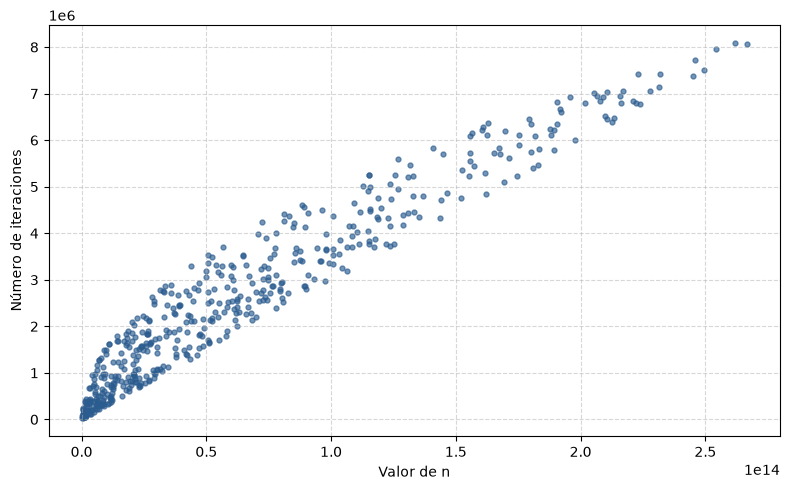

In [17]:
# Gráfico de dispersión con un toque de color y estilo
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))


plt.scatter(
    n_por_ejecucion,
    iteraciones_por_ejecucion,
    alpha=0.65,
    marker=".",
    color="#2b5c8f",
    s=50,  # Tamaño de los puntos
)

plt.xlabel("Valor de n")
plt.ylabel("Número de iteraciones")

plt.grid(True, linestyle="--", alpha=0.5)

# Ajustar márgenes para que no se corte nada
plt.tight_layout()


plt.show()

Con esta prueba de varias ejecuciones, se observa un comportamiento para el número de iteraciones en función de n (a manera heurística) en forma de raíz $n$-ésima.
A saber se estima complejidad $\mathcal{O}(\sqrt{n})$.

Para valores de $n$ más grandes, suponiendo que la complejidad tiene efectivamente forma $\mathcal{O}(\sqrt{n})$ se ve que para dimensiones de $1024\mathrm{b}$ o $2048\mathrm{b}$, 
la complejidad adquiere la siguiente forma:

$1024\mathrm{b} \Longrightarrow n = 2^{1024}$ es decir, la complejidad toma forma de $2^{512}$ iteraciones.
Análogamente, para $2048\mathrm{b}$ la complejidad toma forma de $2^{1024}$ iteraciones.

A continuación se obtiene un valor de referencia rudimentario, específicamente la razón de 
*tiempo promedio por iteración*

In [18]:
tiempo_promedio_iteracion = tiempo_experimento / cantidad_iteraciones

print(f"Tiempo total de ejecución: {tiempo_experimento:.2f} segundos")
print(f"Tiempo promedio por iteración de fuerza bruta: {tiempo_promedio_iteracion * 1000:.2f} ms")

Tiempo total de ejecución: 87.90 segundos
Tiempo promedio por iteración de fuerza bruta: 175.80 ms


Estimación para $2^{512}$ iteraciones:

In [19]:
tiempo_promedio_iteracion_dia = ((tiempo_promedio_iteracion/60)/60)/24
estimacion_casi_maxima = tiempo_promedio_iteracion_dia*pow(2, 512)
print(f" Se estiman {estimacion_casi_maxima} días para un n cualquiera de 1024 bits de longitud.")

 Se estiman 2.7280564455564555e+148 días para un n cualquiera de 1024 bits de longitud.


Nota: No se logró para $2^{1024}$ operaciones, a vista de ser un número extremadamente burdo

### Curvas Elípticas

* **Visualización de una Elípse:** Sea un polininomio evaluado en un espacio de números reales $\mathbb{R}$. Notamos que los términos algebraicos y sus coeficientes producen un efecto elíptico en la visualización. Nos apoyamos en la biblioteca Matplotlib y sus interfaces para graficar nuestros ejemplos.  
ref.: https://matplotlib.org/api/pyplot_summary.html  
ref.: https://matplotlib.org/examples/pylab_examples/contour_demo.html

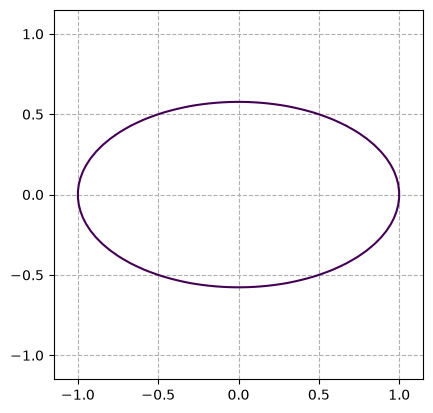

In [20]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-1.0, 1.0, 50)
y = np.linspace(-1.0, 1.0, 50)
X, Y = np.meshgrid(x,y)
F = (1)*(X**2) + (3)*(Y**2) - 1.0
fig, ax = plt.subplots()
ax.contour(X,Y,F,[0])
ax.set_aspect('equal')
plt.xlim(-1.15,1.15)
plt.ylim(-1.15,1.15)
plt.grid(linestyle='--')
plt.show()

* **Curva  elíptica simétrica:** Una elípse es una curva que consiste en un conjunto de puntos en un plano producida por la suma de las distancias f1 y f2 desde un par de puntos fijos y focales F1 y F2 hacia la curva. Donde F1 y F2 se encuentran a una distancia constante 2c. El eje mayor representa la distancia constante 2a y a es el eje semimayor. El eje menor representa la distancia 2b y b es el eje semimenor. Es decir, la elípse es una curva plana cerrada con doble eje de simetría.  
ref: https://mathworld.wolfram.com/Ellipse.html

/tmp/ipykernel_618833/3933977957.py:4: RuntimeWarning: invalid value encountered in sqrt
  y = np.sqrt(-x**2 + 0.7)


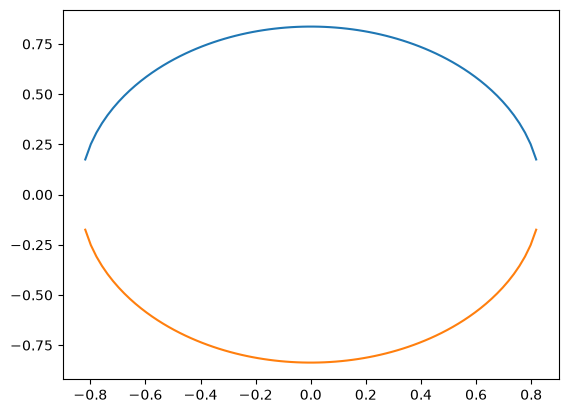

In [21]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-1, 1, 100)
y = np.sqrt(-x**2 + 0.7)
plt.plot(x, y)
plt.plot(x, -y)

* **Grupo Cíclico Extenso:** La elipse puede ofrecer un grupo multiplicativo alternativo a $Z_n^*$. Una curva elíptica es un tipo especial de ecuación polinomial en un campo finito $GF(p)$. En definitiva, una curva elíptica en $Z_p$ con $p>3$, es un conjunto de pares $(x,y)$ que pertenecen a $Z_p$, y cumplen $y^2= x^3+ax+b$ $(mod$ $p)$.

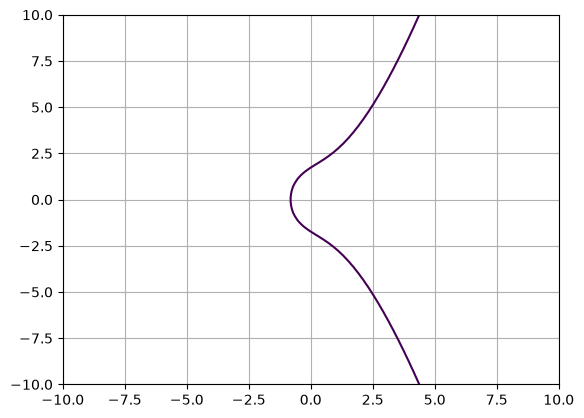

In [22]:
import matplotlib.pyplot as plt 
import numpy as np
y, x = np.ogrid[-10:10:100j, -10:10:100j]
a, b = 3, 3
plt.contour(x.ravel(), y.ravel(), pow(y, 2) - pow(x, 3) - x * a - b, [0])
plt.grid()
plt.show()

* **Elemento Neutro:** Para establecer un grupo finito es necesario un elemento neutro $O$, tal que $P+O=P$ y $P+(-P)=O$. Luego, el inverso del punto es $P = (x_p,-y_p)$, aquel punto reflejado a través del eje $x$.

In [23]:
import numpy as np
def invP(x,y,m):
    yy = (m - y) % m
    iP = np.array([x,yy])
    return iP
P = np.array([4,5])#np.array([8,10])
p = 31#29
print(invP(P[0],P[1],p))

[ 4 26]


* **Operación Adición Punto:** Dado un campo finito primo $GF(p)$, la adición y duplicación de puntos en la curva elíptica satisface $x_3 = s^2 - x_1 - x_2 (mod$ $p)$ ; $y_3 = s(x_1 - x_3) - y_1 (mod$ $p)$. Donde, sí $P \neq 0$, entonces $S = (y_2 - y_1)*(x_2 - x_1)^{(-1)}$.

In [24]:
import numpy as np
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
def poly():
    ec = [1,0,2,2] 
    return (ec[2])
def addP(P,Q,a,m):
    S = ((Q[1]-P[1]) * eea(Q[0]-P[0],m)[1]) % m
    x3 = (pow(S,2) - P[0] - Q[0]) % m
    y3 = (S*(P[0] - x3) - P[1]) % m
    return x3, y3
P = np.array([5,1])
Q = np.array([6,3])
m = 17
R =(addP(P,Q,poly(),m))
print(R)

(np.int64(10), np.int64(6))


* **Operación Duplicación Punto:** Dado un campo finito primo $GF(p)$, la adición y duplicación de puntos en la curva elíptica satisface $x_3 = s^2 - x_1 - x_2 (mod$ $p)$ ; $y_3 = s(x_1 - x_3) - y_1 (mod$ $p)$. Donde, sí $P = 0$, entonces $S = (3x_1^2 +a)*(2y_1)^{(-1)}$

In [25]:
import numpy as np
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
def poly():
    ec = [1,0,2,2]
    return (ec[2])
def duP(P,a,m):
    S = ((3*(pow(P[0],2)) + a) * eea(2*P[1],m)[1] ) % m
    x3 = (pow(S,2) - 2*P[0]) % m
    y3 = (S*(P[0] - x3) - P[1]) % m
    return x3, y3
P = np.array([5,1])
m = 31#17
R = duP(P,poly(),m)
print(R)

(np.int64(23), np.int64(19))


* **Cardinalidad:** Dada una curva elíptica $E$ modulo $p$, el número de puntos en la curva se denota como $\#E$ y se encuentra entre los límites $\#E > p+1-2sqrt(p)$ y $\#E < p+1+2sqrt(p)$.  
 _Código adaptado_
Ref: https://crypto.stackexchange.com/users/73222/

In [26]:
import math
p = 23
left = p + 1 - 2*(math.sqrt(p))
right = p + 1 + 2*(math.sqrt(p))
print(left, right)
campo = pow(2,p) - pow(2,11)
print(campo)

14.408336953374562 33.59166304662544
8386560


In [3]:
import numpy as np
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
def poly():
    ec = [1,5,12] 
    return (ec[1])
def oP(P,Q,a,m):
    for i in range(2,50):
        if (P[0] == Q[0] and P[1] == Q[1]):
         S=((3*(pow(P[0],2)) + a) * eea(2*P[1],m)[1] ) % m
        else:
         S=((Q[1]-P[1]) * eea(Q[0]-P[0],m)[1]) % m
        x3=(pow(S,2) - P[0] - Q[0]) % m
        y3=(S*(P[0] - x3) - P[1]) % m
        print(str(i) + "P:\t", (x3,y3))
        Q[0],Q[1]=x3, y3 
P = np.array([4,5])
Q = np.array([7,21])
m = 17#31#29#17
print("1P:\t", (P[0],P[1]))
oP(P,Q,poly(),m)

1P:	 (np.int64(4), np.int64(5))
2P:	 (np.int64(8), np.int64(2))
3P:	 (np.int64(13), np.int64(6))
4P:	 (np.int64(4), np.int64(12))
5P:	 (np.int64(9), np.int64(12))
6P:	 (np.int64(8), np.int64(3))
7P:	 (np.int64(1), np.int64(2))
8P:	 (np.int64(16), np.int64(5))
9P:	 (np.int64(14), np.int64(12))
10P:	 (np.int64(0), np.int64(8))
11P:	 (np.int64(0), np.int64(3))
12P:	 (np.int64(11), np.int64(10))
13P:	 (np.int64(15), np.int64(9))
14P:	 (np.int64(6), np.int64(2))
15P:	 (np.int64(5), np.int64(5))
16P:	 (np.int64(8), np.int64(12))
17P:	 (np.int64(7), np.int64(11))
18P:	 (np.int64(10), np.int64(0))
19P:	 (np.int64(7), np.int64(6))
20P:	 (np.int64(8), np.int64(5))
21P:	 (np.int64(5), np.int64(12))
22P:	 (np.int64(6), np.int64(15))
23P:	 (np.int64(15), np.int64(8))
24P:	 (np.int64(11), np.int64(7))
25P:	 (np.int64(0), np.int64(1))
26P:	 (np.int64(5), np.int64(9))
27P:	 (np.int64(7), np.int64(0))
28P:	 (np.int64(5), np.int64(8))
29P:	 (np.int64(0), np.int64(7))
30P:	 (np.int64(11), np.int64(14))
3

**Actividad 3:** La multiplicación punto es análoga a la exponenciación de grupos multiplicativos. El algoritmo de cuadrados-y-multiplicaciones (square-and-multiply) puede ser usado para calcular las operaciones de adición y duplicación de puntos, donde el cómputo del cuadrado se transforma en la operación duplicación y la multiplicación se torna en la adición de $P$. Si $P$ es un punto inicial y $T$ es un punto final, luego $dP = T$ y es el número de saltos en la curva elítpica. Proponga una solución programática que demuestre la multiplicación punto. Señale los supuestos escogidos considerando el siguiente pseudocódigo.

Algorithm:


---



```
FOR i = t − 1 DOWNTO 0
    T = T + T mod n 
        IF di = 1 
            T = T + P mod n 2
RETURN (T)
```

### Supuestos escogidos
Los supuestos escogidos para la implementacion de la multiplicacion punto  utilizando el algoritmo square and multiply son los siguientes

1. **Parámetros de la curva y punto inicial:** Se utiliza la misma curva elíptica $y^2 \equiv x^3 + ax + b \pmod n$ de los ejemplos anteriores, donde el módulo es $n = 17$, el parámetro $a = 2$ se obtiene de `poly()` (`ec = [1, 0, 2, 2]`) y el punto inicial es $P = (5, 1)$.
2. **Condición inicial ($T = P$) y lectura binaria de $d$:** Si escribimos el escalar $d$ en binario como $(d_t, d_{t-1}, \dots, d_0)_2$, el bit más significativo ($d_t$) siempre vale $1$. Por lo tanto, se asume que antes de iniciar el ciclo `FOR i = t - 1 DOWNTO 0` el punto acumulador parte inicializado en **$T = P$**, y el ciclo recorre los bits restantes (`binarray[1:]`) desde el segundo bit hasta el último.
3. **Operaciones de duplicación y adición:**
   - La línea `T = T + T mod n` suma el mismo punto dos veces, por lo que se traduce directamente en la función de duplicación `duP(T, a, n)`.
   - La línea `T = T + P mod n` (cuando `di == 1`) suma dos puntos distintos de la curva ($T \neq P$), por lo que se traduce en la función de adición `addP(T, P, a, n)` reduciendo `(Q[0]-P[0]) % m` y `(2*P[1]) % m` para mantener el argumento de `eea` positivo dentro de $\mathbb{Z}_n$.
4. **Número de saltos acotado al orden del grupo:** Se escoge un número de saltos $d$ menor al orden del grupo cíclico ($1 \le d < 19$, por ejemplo $d = 13$), 

In [9]:
# escriba aquí su código y markdown
import numpy as np
print((-16)*(pow(4*11,3)+pow(27*8,2)))

def addP(P,Q,a,m):
    S = ((Q[1]-P[1]) * eea((Q[0]-P[0]) % m, m)[1]) % m
    x3 = (pow(S,2) - P[0] - Q[0]) % m
    y3 = (S*(P[0] - x3) - P[1]) % m
    return x3, y3

def duP(P,a,m):
    S = ((3*(pow(P[0],2)) + a) * eea((2*P[1]) % m, m)[1]) % m
    x3 = (pow(S,2) - 2*P[0]) % m
    y3 = (S*(P[0] - x3) - P[1]) % m
    return x3, y3

def multP(P, d, a, n):
    T = (int(P[0]), int(P[1]))
    numero_entero = int(d)
    cadena_binaria = format(numero_entero, 'b') 
    binarray = []
    for caracter in cadena_binaria:
        bit = int(caracter)
        binarray.append(bit)

    
    for di in binarray[1:]:
        T = duP(T, a, n)
        if di == 1:
            T = addP(T, P, a, n)
    return (int(T[0]), int(T[1]))

P = np.array([5, 1])
n = 17
d = 13

T = multP(P, d, poly(), n)
print(f"Punto inicial P: {(int(P[0]), int(P[1]))}")
print(f"Saltos d:{d}, a binario: {bin(d)[2:]}")
print(f"{d} +  P = T:{T}")
print("\nDemostracion de saltos dP = T:")
for i in range(1, 19):
    print(f"{str(i)} + P:, {multP(P, i, poly(), n)}")

-2109440
Punto inicial P: (5, 1)
Saltos d:13, a binario: 1101
13 +  P = T:(7, 5)

Demostracion de saltos dP = T:
1 + P:, (5, 1)
2 + P:, (9, 9)
3 + P:, (7, 12)
4 + P:, (14, 9)
5 + P:, (16, 10)
6 + P:, (11, 8)
7 + P:, (0, 2)
8 + P:, (10, 0)
9 + P:, (0, 15)
10 + P:, (11, 9)
11 + P:, (16, 7)
12 + P:, (14, 8)
13 + P:, (7, 5)
14 + P:, (9, 8)
15 + P:, (5, 16)
16 + P:, (14, 0)
17 + P:, (2, 10)
18 + P:, (9, 9)


In [29]:
import math
Alice= (3**41 % 43) # Alice
Bob= (3**4 % 43) # Bob
print(Bob**41 % 43) # Shared Secret Alice
print(Alice**4 % 43) # Shared Secret Bob
print(Alice)
print(Bob)
#print(math.log(41,11) % 43)
#print(math.log(3,72) % 43)
#print(3**72 % 43)
#print(41**72 % 43)
#print(41**11 % 43)
print(3**45 % 43)
print(3**164 % 43)

17
17
29
38
27
17


In [30]:
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
n=9797
e=131
x1 = 123
x2 = 4333
print(eea(131,9600))
print(x1**3371 % n)
#print(x2**131 % )
#print(6292^131 % 9600)
#print(1024^131 % 9600)
#print(4768^131 % 9600)
#print(1424^131 % 9600)

#print(math.gcd(7,96))

(1, np.int64(3371), np.int64(-46))
6292


In [31]:
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
p = 59
q = 29
a = 3
d = 23 #7    
B = a**d % p
print(B)
Hx = 2 #26
Ke = 13 #13 #10
r= (a**Ke % p) % q
s= ((Hx + (d*r)) * eea(Ke,q)[1]) % q
print(r,s, eea(Ke,q)[1])
w = eea(s,q)[1] % q
u1= w*Hx % q
u2= w*r % q
print(w,u1,u2) 
v0 = (a**u1) % p
v1 = (B**u2) % p
v = (v0 * v1 % p) % q
print(r,v)


45
25 2 9
15 1 27
25 9


**Actividad 4:** Compare el desempeño de (dP) en dos modelos afines: Weierstrass y Montgomery, reusando el double-and-add de la Actividad 3. El objetivo no es “romper” la curva, sino medir por qué Montgomery suele ser más eficiente en multiplicación por escalar (aritmética (x)-only, escalera regular) frente a Weierstrass afín (inversiones en cada suma/doble).

- Weierstrass corta: $(y^2 = x^3 + ax + b)$
- Montgomery: $(By^2 = x^3 + Ax^2 + x)$

### Fin de la Tarea!!!